# 1 · Setup: what we compare, and what the model actually sees

*Part 1 of the analysis story. Next: `02_full_context.ipynb`.*

**The question.** Does lexicographic knowledge help an LLM pick the right word sense?
We ask the same 36 questions with the same model (temperature 0) under five
context regimes that differ *only* in what the model is allowed to see.

| Variant | What the model sees |
|---|---|
| **A** - base LLM | nothing; it must describe the sense from its own knowledge |
| **B** - text RAG | the 3 sense chunks (definition + lemma) that are closest to the question by embedding similarity, searched over **all 131,056 senses** of the dictionary |
| **C** - dictionary list | the target lemma's own senses, in **dictionary order**, with definitions, synonyms and typical collocations ("Zveze") |
| **D** - graph-ranked | the **same candidates** as C, but ordered by how well the sentence matches each sense's graph neighbourhood (collocations, synonyms, WordNet synsets) |
| **oracle** - ceiling | the gold sense plus its nearest siblings - the right answer is guaranteed to be on the table |

The **budget** is the maximum number of candidates shown to the model
(`structured.max_senses` / `graph.max_candidates`). We ran four regimes:
budget 1, 2, 3, and "all" (12).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import elexai.analysis as al

al.scientific_style()
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.width", 220)


FULL = al.find_run("skeleton")  # the full-context run (all 36 questions)
full = al.load_answers(FULL)
questions = al.load_questions_table()
senses = al.load_senses_table()
print("run:", FULL, "| answers:", len(full), "| questions:", len(questions))

run: 20261022-091557_skeleton | answers: 180 | questions: 36


## What is in the question set?

36 hand-written questions, all still **drafts** until a lexicographer verifies them:
30 sense-disambiguation questions ("which sense of this word is used in this sentence?")
and 6 relation questions ("which sense of word X is the synonym / hypernym / antonym
of this given sense?"). Two items are flagged `trick` - they are known to be
problematic (we meet them in notebook 2).

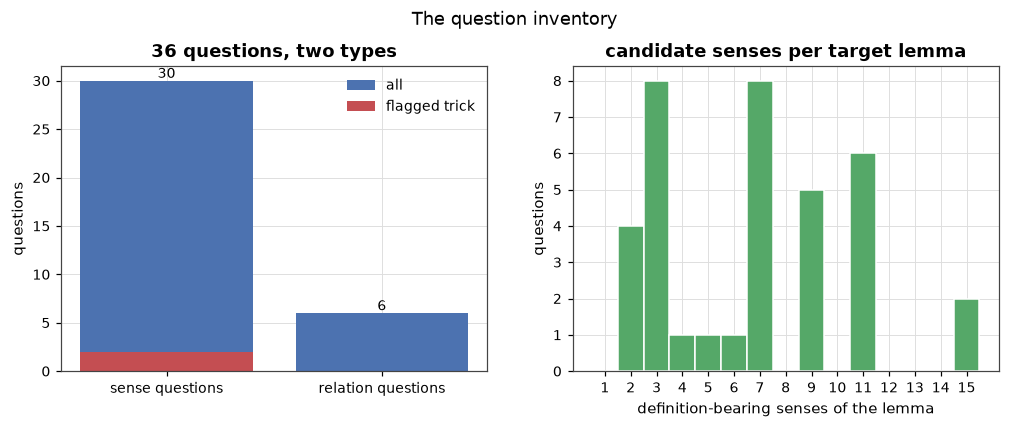

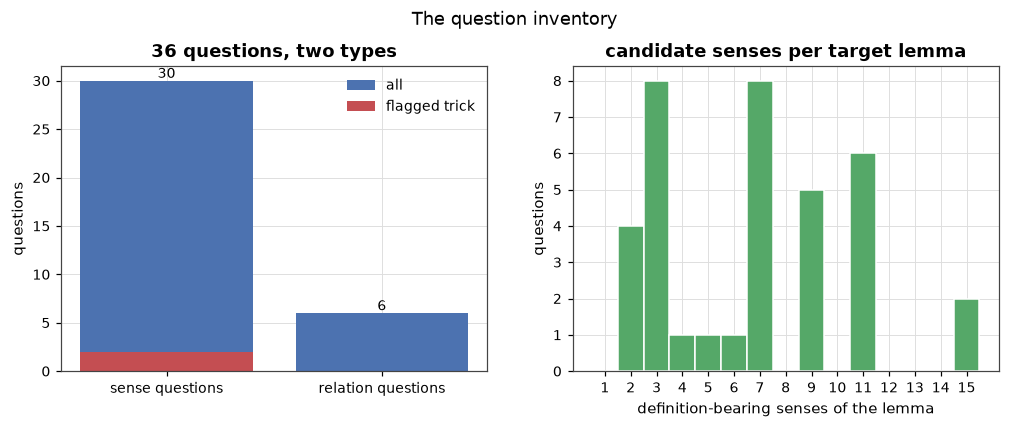

In [2]:
n_senses = senses.groupby("lemma")["sense_id"].count()
q = questions.assign(n_senses=questions["lemma"].map(n_senses))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

ax = axes[0]
labels = ["sense questions", "relation questions"]
vals = [int((q["question_type"] == "sense_disambiguation").sum()), int((q["question_type"] == "relation").sum())]
trick = [int(((q["question_type"] == t) & q["is_trick"]).sum()) for t in ("sense_disambiguation", "relation")]
ax.bar(labels, vals, color="#4c72b0", label="all")
ax.bar(labels, trick, color="#c44e52", label="flagged trick")
for i, v in enumerate(vals):
    ax.text(i, v + 0.3, str(v), ha="center", fontsize=9)
ax.set_title("36 questions, two types")
ax.set_ylabel("questions")
ax.legend(loc="upper right")

ax = axes[1]
maxn = int(q["n_senses"].max())
ax.hist(q["n_senses"], bins=np.arange(1, maxn + 2) - 0.5, color="#55a868", edgecolor="white")
ax.set_xticks(range(1, maxn + 1))
ax.set_title("candidate senses per target lemma")
ax.set_xlabel("definition-bearing senses of the lemma")
ax.set_ylabel("questions")

fig.suptitle("The question inventory", y=1.02)
al.save_figure(fig, "01_question_inventory")
fig

> **Reading the chart.** The set mixes easy 2-way contrasts with harder
> late-position senses; every lemma has 2-5 candidates, so the full context
> (budget 12) always fits on screen. The two red questions are the flagged
> `trick` items - notebook 2 shows exactly what is wrong with them.

> **Takeaway.** Candidate sets are small (2-5 senses). That is the design
> choice that makes the whole comparison possible: when everything fits in
> the prompt, *finding* candidates is free and only *choosing* remains -
> until we deliberately shrink the budget in notebook 3.

## A worked example: the same question, five contexts

Question `q-001` asks which sense of **kos** is used in
*"Kuhar je odrezal tanek kos kruha in ga položil na krožnik."*
Below is the actual context block each variant saw (extracted from the run's
logged prompts; long blocks are truncated).

In [3]:
def context_block(prompt: str) -> str:
    return prompt.split("Možni pomeni:")[1].split("Odgovori natanko")[0].strip()

for v in ["A", "B", "C", "D", "oracle"]:
    row = full[(full["variant"] == v) & (full["question_id"] == "q-001")].iloc[0]
    block = context_block(row["prompt"])
    print("=" * 26, al.VARIANT_LABELS[v], "=" * 26)
    print(block[:650] + (" …" if len(block) > 650 else ""))
    print()

========================== A - base LLM ==========================
(Ni na voljo.)

========================== B - text RAG ==========================
ID: 16276239
Beseda: krušen (adjective)
Definicija: v kulinariki | majhen, na kocke narezan kos kruha, ki se uporablja kot dodatek k jedem ali kot sestavina zanje

ID: 16276234
Beseda: kruhov (adjective)
Definicija: v kulinariki | majhen, na kocke narezan kos kruha, ki se kot dodatek ali sestavina uporablja pri pripravi različnih jedi, zlasti juh in solat

ID: 16260871
Beseda: kruh (noun)
Definicija: živilo

========================== C - dictionary list ==========================
ID: 16282392
Beseda: kos (noun)
Definicija: delež, ponavadi od dobička | delež česa, navadno dobička ali koristi, ki pripada komu

ID: 16283272
Beseda: kos (noun)
Definicija: del celote | del snovi, predmeta ali živila, navadno ločen od večje celote
Zveze: kos lesa, kos mesa, kos kruha, kos torte, kos sira, debel kos, tanek kos, odrezati kos

ID: 16283275
Beseda

> **What we see.**
> - **A** gets nothing and cannot cite an ID at all.
> - **B** retrieved three definition chunks from *anywhere* in the dictionary -
>   for this question they are not even senses of *kos* (open search has no
>   idea which lemma the question is about).
> - **C** lists the senses of *kos* in dictionary order.
> - **D** shows the same senses, reordered by neighbourhood match (here: the
>   collocation "kos kruha" ranks the "piece" sense first).
> - **oracle** guarantees the gold sense plus its neighbours.

> **Takeaway.** C and D differ only in *ordering* (and, as we document in
> notebook 3, slightly in which synonym/collocation forms are printed).
> A and B are the two "no dictionary entry" baselines.

## Four budgets: why we truncate

With all candidates visible, ordering cannot matter - there is nothing to
rank *out*. To test the ranking itself, we re-ran the same questions with
budgets of **3, 2 and 1** candidates. Everything else (model, questions,
prompts for A/B) stayed identical.

**Key facts to carry forward**

| Fact | Value |
|---|---|
| questions | 36 (30 sense + 6 relation; 2 flagged trick) |
| runs available | full-context, budget 3, budget 2, budget 1 |
| model | `openai/gpt-6-luna`, temperature 0, identical across variants |
| dictionary | DDDS snapshot, 131,056 definition-bearing senses |
| graph | DDDS sense relations + WordNet synsets + OEWN hierarchy (Neo4j) |